# ============================================================
# ROCOv2 EDA
# Radiology Objects in COntext Version 2
# ============================================================
#
# Research Project:
# Trustworthy Multimodal Medical Decision Support
#
# Dataset:
# ROCOv2
#
# Purpose:
# Comprehensive exploratory data analysis before
# multimodal VLM development.
# ============================================================

In [ ]:
# Mount Google Drive
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Imports and configuration
import os
import zipfile
import warnings
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from collections import Counter

from PIL import Image

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Base directory
# ------------------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/ROCOv2"

META_DIR = os.path.join(
    BASE_DIR,
    "Processed_Metadata"
)

EDA_DIR = os.path.join(
    BASE_DIR,
    "EDA_Results"
)

os.makedirs(
    EDA_DIR,
    exist_ok=True
)

print("BASE_DIR:", BASE_DIR)
print("META_DIR:", META_DIR)
print("EDA_DIR:", EDA_DIR)

BASE_DIR: /content/drive/MyDrive/ROCOv2
META_DIR: /content/drive/MyDrive/ROCOv2/Processed_Metadata
EDA_DIR: /content/drive/MyDrive/ROCOv2/EDA_Results


In [ ]:
# Load metadata
train_df = pd.read_csv(
    os.path.join(
        META_DIR,
        "train_metadata.csv"
    )
)

valid_df = pd.read_csv(
    os.path.join(
        META_DIR,
        "valid_metadata.csv"
    )
)

test_df = pd.read_csv(
    os.path.join(
        META_DIR,
        "test_metadata.csv"
    )
)

print("Train:", train_df.shape)
print("Validation:", valid_df.shape)
print("Test:", test_df.shape)

Train: (59958, 9)
Validation: (9904, 9)
Test: (9927, 9)


In [ ]:
dataset_summary = pd.DataFrame({
    "Split": [
        "Train",
        "Validation",
        "Test"
    ],
    "Samples": [
        len(train_df),
        len(valid_df),
        len(test_df)
    ]
})

dataset_summary["Percentage"] = (
    dataset_summary["Samples"]
    / dataset_summary["Samples"].sum()
    * 100
)

display(dataset_summary)

print(
    "\nTotal samples:",
    dataset_summary["Samples"].sum()
)

,Split,Samples,Percentage
0,Train,59958,75.145697
1,Validation,9904,12.412739
2,Test,9927,12.441565



Total samples: 79789


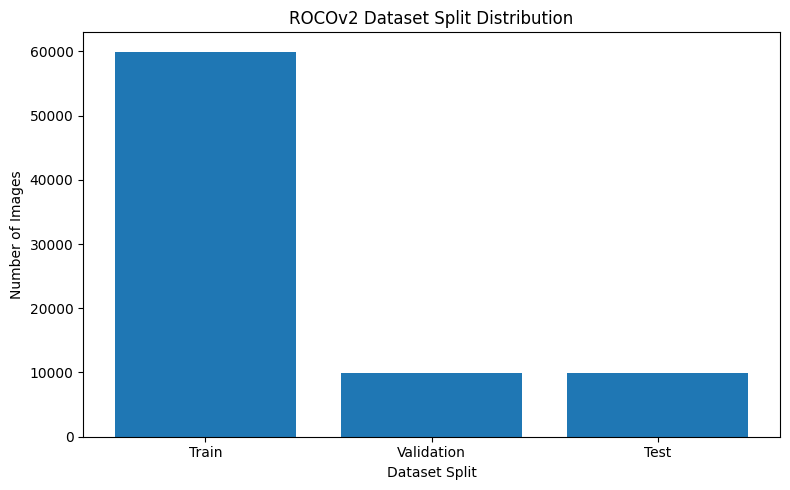

In [ ]:
# Split distribution plot
plt.figure(figsize=(8, 5))

plt.bar(
    dataset_summary["Split"],
    dataset_summary["Samples"]
)

plt.title("ROCOv2 Dataset Split Distribution")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Images")

plt.tight_layout()

plt.savefig(
    os.path.join(
        EDA_DIR,
        "dataset_split_distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Verify metadata columns
print("Metadata columns:")
print()

for column in train_df.columns:
    print(
        f"{column:25} "
        f"dtype={train_df[column].dtype}"
    )

Metadata columns:

ID                        dtype=object
Image_Path                dtype=object
Caption                   dtype=object
Manual_CUIs               dtype=object
Manual_Concepts           dtype=object
Modality_Labels           dtype=object
Anatomy_Labels            dtype=object
Direction_Labels          dtype=object
Image_Exists              dtype=bool


In [ ]:
# Missing-value analysis
def missing_analysis(df, name):

    result = pd.DataFrame({
        "Missing_Count": df.isna().sum(),
        "Missing_Percentage":
            df.isna().mean() * 100
    })

    result = result.sort_values(
        "Missing_Count",
        ascending=False
    )

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    display(result)


missing_analysis(train_df, "TRAIN")
missing_analysis(valid_df, "VALIDATION")
missing_analysis(test_df, "TEST")


TRAIN


,Missing_Count,Missing_Percentage
Direction_Labels,47557,79.317189
Anatomy_Labels,43734,72.941059
Modality_Labels,493,0.822242
Manual_Concepts,493,0.822242
Manual_CUIs,493,0.822242
ID,0,0.000000
Caption,0,0.000000
Image_Path,0,0.000000
Image_Exists,0,0.000000



VALIDATION


,Missing_Count,Missing_Percentage
Direction_Labels,7927,80.038368
Anatomy_Labels,7374,74.454766
Modality_Labels,130,1.312601
Manual_Concepts,130,1.312601
Manual_CUIs,130,1.312601
ID,0,0.000000
Caption,0,0.000000
Image_Path,0,0.000000
Image_Exists,0,0.000000



TEST


,Missing_Count,Missing_Percentage
Direction_Labels,7921,79.792485
Anatomy_Labels,7336,73.899466
Modality_Labels,105,1.057721
Manual_Concepts,105,1.057721
Manual_CUIs,105,1.057721
ID,0,0.000000
Caption,0,0.000000
Image_Path,0,0.000000
Image_Exists,0,0.000000


In [ ]:
# Duplicate ID analysis
for name, df in [
    ("Train", train_df),
    ("Validation", valid_df),
    ("Test", test_df)
]:

    duplicate_ids = df["ID"].duplicated().sum()

    print(
        f"{name:15} duplicate IDs: "
        f"{duplicate_ids}"
    )

Train           duplicate IDs: 0
Validation      duplicate IDs: 0
Test            duplicate IDs: 0


In [ ]:
# Caption statistics
def caption_statistics(df, name):

    captions = df["Caption"].fillna("").astype(str)

    word_counts = captions.apply(
        lambda x: len(x.split())
    )

    char_counts = captions.apply(len)

    stats = {
        "Samples": len(df),
        "Empty captions": (captions.str.strip() == "").sum(),
        "Average words": word_counts.mean(),
        "Median words": word_counts.median(),
        "Minimum words": word_counts.min(),
        "Maximum words": word_counts.max(),
        "Average characters": char_counts.mean(),
        "Median characters": char_counts.median()
    }

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    for key, value in stats.items():
        print(
            f"{key:25}: "
            f"{value:.2f}" if isinstance(value, float)
            else f"{key:25}: {value}"
        )

    return word_counts


train_caption_words = caption_statistics(
    train_df,
    "TRAIN CAPTIONS"
)

valid_caption_words = caption_statistics(
    valid_df,
    "VALIDATION CAPTIONS"
)

test_caption_words = caption_statistics(
    test_df,
    "TEST CAPTIONS"
)


TRAIN CAPTIONS
Samples                  : 59958
Empty captions           : 0
Average words            : 20.56
Median words             : 17.00
Minimum words            : 1
Maximum words            : 410
Average characters       : 140.54
Median characters        : 117.00

VALIDATION CAPTIONS
Samples                  : 9904
Empty captions           : 1
Average words            : 21.90
Median words             : 17.00
Minimum words            : 0
Maximum words            : 633
Average characters       : 150.51
Median characters        : 122.00

TEST CAPTIONS
Samples                  : 9927
Empty captions           : 0
Average words            : 22.04
Median words             : 18.00
Minimum words            : 1
Maximum words            : 778
Average characters       : 151.30
Median characters        : 125.00


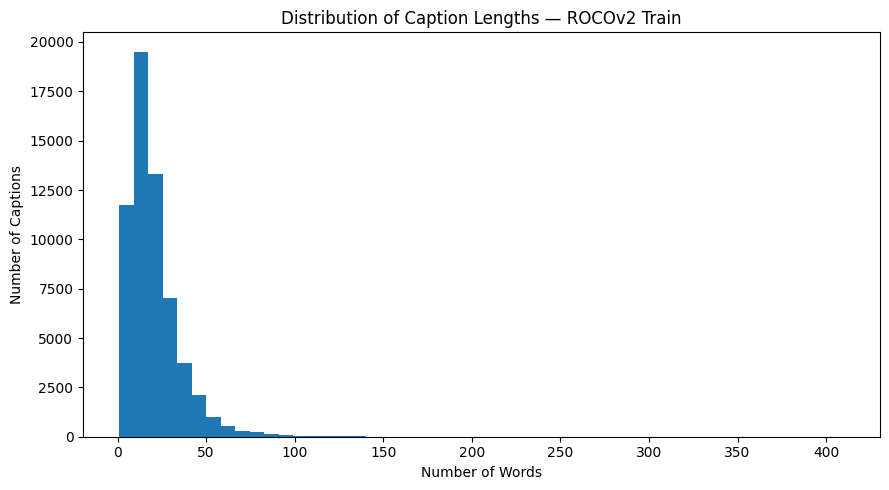

In [ ]:
# Caption length distribution
plt.figure(figsize=(9, 5))

plt.hist(
    train_caption_words,
    bins=50
)

plt.title(
    "Distribution of Caption Lengths — ROCOv2 Train"
)

plt.xlabel("Number of Words")
plt.ylabel("Number of Captions")

plt.tight_layout()

plt.savefig(
    os.path.join(
        EDA_DIR,
        "caption_length_distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Shortest and longest captions
temp = train_df.copy()

temp["Word_Count"] = (
    temp["Caption"]
    .fillna("")
    .astype(str)
    .apply(lambda x: len(x.split()))
)

print("Shortest captions:")
display(
    temp.sort_values(
        "Word_Count"
    )[["ID", "Caption", "Word_Count"]].head(10)
)

print("\nLongest captions:")
display(
    temp.sort_values(
        "Word_Count",
        ascending=False
    )[["ID", "Caption", "Word_Count"]].head(10)
)

Shortest captions:


,ID,Caption,Word_Count
9408,ROCOv2_2023_train_009436,Orthopantogram.,1
58338,ROCOv2_2023_train_058537,Hepatomegaly.,1
58339,ROCOv2_2023_train_058538,Splenomegaly.,1
7269,ROCOv2_2023_train_007290,Postobturation.,1
24224,ROCOv2_2023_train_024309,Ortopantomography.,1
35517,ROCOv2_2023_train_035633,Cephalogram,1
49946,ROCOv2_2023_train_050100,Malunion,1
54855,ROCOv2_2023_train_055037,X-ray,1
38355,ROCOv2_2023_train_038482,Orthopantomograph.,1
38569,ROCOv2_2023_train_038697,Pseudoaneurysm,1



Longest captions:


,ID,Caption,Word_Count
46483,ROCOv2_2023_train_046629,"In the meantime, additional diagnostic work-up...",410
57531,ROCOv2_2023_train_057727,Additional diagnostic workup drawn a day prior...,368
46482,ROCOv2_2023_train_046628,A 50-year old woman of Indian descent living i...,326
51735,ROCOv2_2023_train_051897,Regions of interest (ROIs) created in ImageJ: ...,297
54020,ROCOv2_2023_train_054197,Thyroid ultrasound revealed a 14x14x22 mm nodu...,244
35968,ROCOv2_2023_train_036084,Measurement and classification of the impacted...,227
57530,ROCOv2_2023_train_057726,A 21-year-old man presented with 6 weeks of un...,211
48987,ROCOv2_2023_train_049136,Ultrasound vector flow imaging of laminar flow...,208
25947,ROCOv2_2023_train_026038,This 75 year old female with chronic pancreati...,203
41203,ROCOv2_2023_train_041337,Angle indicators on the lateral cervical X-ray...,200


In [ ]:
# Manual concept frequency function
def concept_counter(df):

    counter = Counter()

    for value in df["Manual_CUIs"].fillna(""):

        for cui in str(value).split(";"):

            cui = cui.strip()

            if cui:
                counter[cui] += 1

    return counter


train_manual_counts = concept_counter(train_df)
valid_manual_counts = concept_counter(valid_df)
test_manual_counts = concept_counter(test_df)

print(
    "Unique manual concepts:",
    len(train_manual_counts)
)

Unique manual concepts: 18


In [ ]:
# CUI mapping
cui_mapping = pd.read_csv(
    os.path.join(
        BASE_DIR,
        "cui_mapping.csv"
    )
)

cui_dict = dict(
    zip(
        cui_mapping["CUI"].astype(str),
        cui_mapping["Canonical name"].astype(str)
    )
)

print(
    "CUI mapping entries:",
    len(cui_dict)
)

CUI mapping entries: 1934


In [ ]:
# Manual concept table
manual_concept_table = pd.DataFrame({

    "CUI": list(train_manual_counts.keys()),

    "Concept": [
        cui_dict.get(
            cui,
            "Unknown"
        )
        for cui in train_manual_counts.keys()
    ],

    "Train": [
        train_manual_counts[cui]
        for cui in train_manual_counts.keys()
    ],

    "Validation": [
        valid_manual_counts.get(cui, 0)
        for cui in train_manual_counts.keys()
    ],

    "Test": [
        test_manual_counts.get(cui, 0)
        for cui in train_manual_counts.keys()
    ]
})

manual_concept_table = manual_concept_table.sort_values(
    "Train",
    ascending=False
).reset_index(drop=True)

display(manual_concept_table)

,CUI,Concept,Train,Validation,Test
0,C0040405,X-Ray Computed Tomography,20459,3673,3615
1,C1306645,Plain x-ray,16603,2670,2724
2,C0024485,Magnetic Resonance Imaging,9790,1444,1423
3,C0041618,Ultrasonography,8305,1528,1596
4,C1999039,Anterior-Posterior,7111,1241,1253
5,C0817096,Chest,5463,948,977
6,C0002978,angiogram,3958,421,420
7,C1996865,Postero-Anterior,3393,445,465
8,C0037303,Bone structure of cranium,3216,379,378
9,C0023216,Lower Extremity,2293,428,446


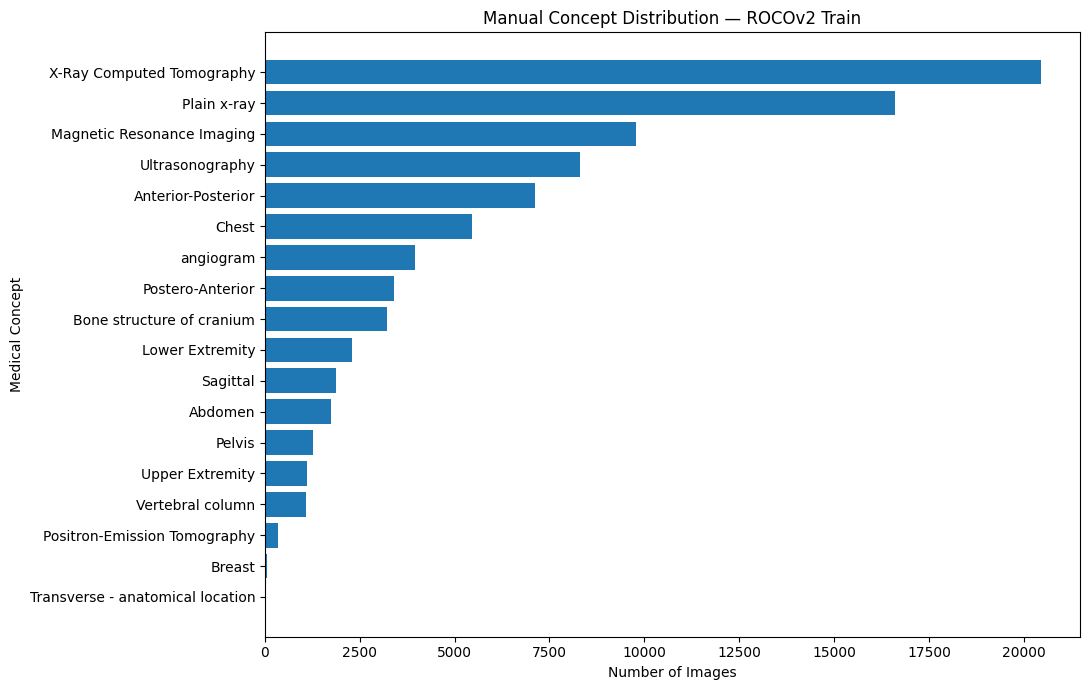

In [ ]:
# Manual concept imbalance
plt.figure(figsize=(11, 7))

plt.barh(
    manual_concept_table["Concept"],
    manual_concept_table["Train"]
)

plt.title(
    "Manual Concept Distribution — ROCOv2 Train"
)

plt.xlabel("Number of Images")
plt.ylabel("Medical Concept")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig(
    os.path.join(
        EDA_DIR,
        "manual_concept_distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Modality distribution
def group_counter(df, column):

    counter = Counter()

    for value in df[column].fillna(""):

        for label in str(value).split(";"):

            label = label.strip()

            if label:
                counter[label] += 1

    return counter


modality_counts = group_counter(
    train_df,
    "Modality_Labels"
)

modality_table = pd.DataFrame({
    "Modality": list(modality_counts.keys()),
    "Train": list(modality_counts.values())
})

modality_table = modality_table.sort_values(
    "Train",
    ascending=False
)

display(modality_table)

,Modality,Train
0,CT,20459
4,Plain X-ray,16603
3,MRI,9790
1,Ultrasound,8305
2,Angiogram,3958
5,PET,350


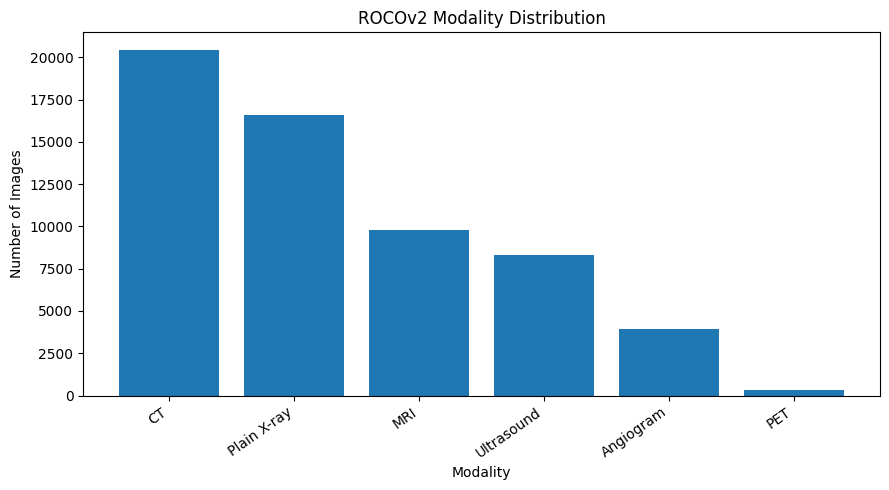

In [ ]:
# Modality plot
plt.figure(figsize=(9, 5))

plt.bar(
    modality_table["Modality"],
    modality_table["Train"]
)

plt.title(
    "ROCOv2 Modality Distribution"
)

plt.xlabel("Modality")
plt.ylabel("Number of Images")

plt.xticks(
    rotation=35,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        EDA_DIR,
        "modality_distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Anatomy distribution
anatomy_counts = group_counter(
    train_df,
    "Anatomy_Labels"
)

anatomy_table = pd.DataFrame({
    "Anatomy": list(anatomy_counts.keys()),
    "Train": list(anatomy_counts.values())
})

anatomy_table = anatomy_table.sort_values(
    "Train",
    ascending=False
)

display(anatomy_table)

,Anatomy,Train
0,Chest,5463
3,Cranium,3216
2,Lower Extremity,2293
1,Abdomen,1747
4,Pelvis,1257
5,Upper Extremity,1119
6,Vertebral Column,1073
7,Breast,56


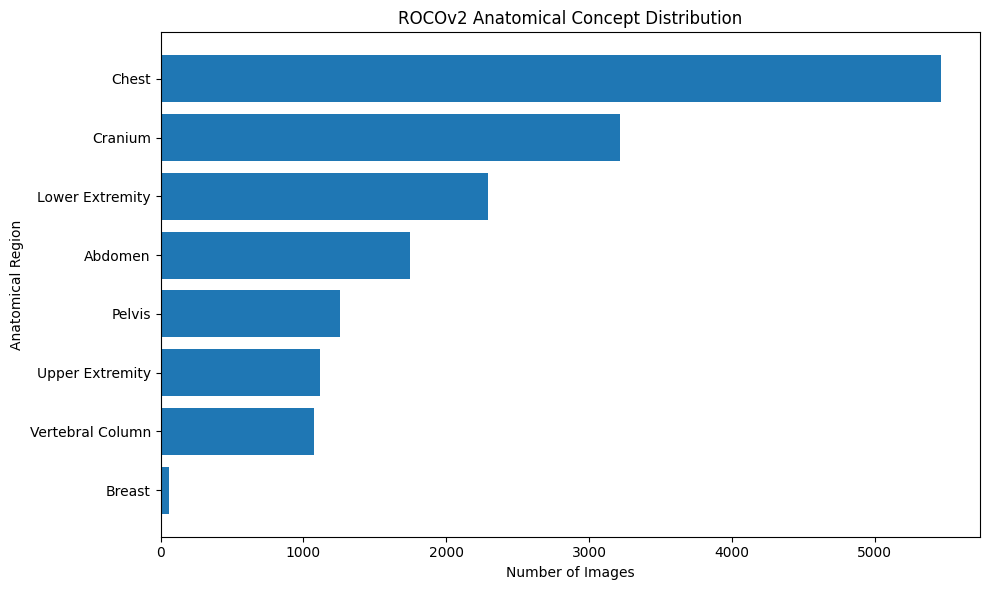

In [ ]:
# Anatomy plot
plt.figure(figsize=(10, 6))

plt.barh(
    anatomy_table["Anatomy"],
    anatomy_table["Train"]
)

plt.title(
    "ROCOv2 Anatomical Concept Distribution"
)

plt.xlabel("Number of Images")
plt.ylabel("Anatomical Region")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig(
    os.path.join(
        EDA_DIR,
        "anatomy_distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Directionality distribution
direction_counts = group_counter(
    train_df,
    "Direction_Labels"
)

direction_table = pd.DataFrame({
    "Direction": list(direction_counts.keys()),
    "Train": list(direction_counts.values())
})

direction_table = direction_table.sort_values(
    "Train",
    ascending=False
)

display(direction_table)

,Direction,Train
1,AP,7111
0,PA,3393
2,Sagittal,1868
3,Transverse,29


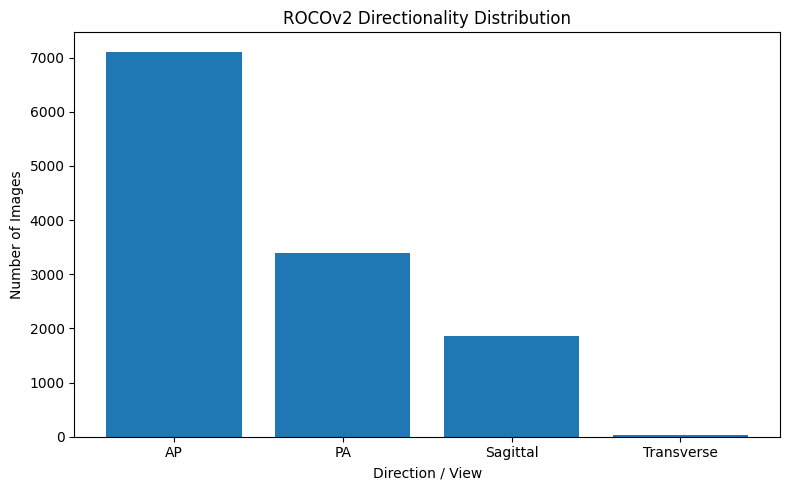

In [ ]:
# Directionality plot
plt.figure(figsize=(8, 5))

plt.bar(
    direction_table["Direction"],
    direction_table["Train"]
)

plt.title(
    "ROCOv2 Directionality Distribution"
)

plt.xlabel("Direction / View")
plt.ylabel("Number of Images")

plt.tight_layout()

plt.savefig(
    os.path.join(
        EDA_DIR,
        "directionality_distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Number of concepts per image
def number_of_labels(series):

    return series.fillna("").apply(
        lambda x: len([
            c for c in str(x).split(";")
            if c.strip()
        ])
    )


train_num_concepts = number_of_labels(
    train_df["Manual_CUIs"]
)

print(
    train_num_concepts.describe()
)

count    59958.000000
mean         1.469195
std          0.819710
min          0.000000
25%          1.000000
50%          1.000000
75%          2.000000
max          3.000000
Name: Manual_CUIs, dtype: float64


In [ ]:
# Multi-label distribution
label_distribution = (
    train_num_concepts
    .value_counts()
    .sort_index()
)

print(
    "Number of manual concepts per image:"
)

display(
    label_distribution.to_frame(
        "Number_of_Images"
    )
)


Number of manual concepts per image:


,Number_of_Images
Manual_CUIs,
0,493
1,43024
2,4257
3,12184


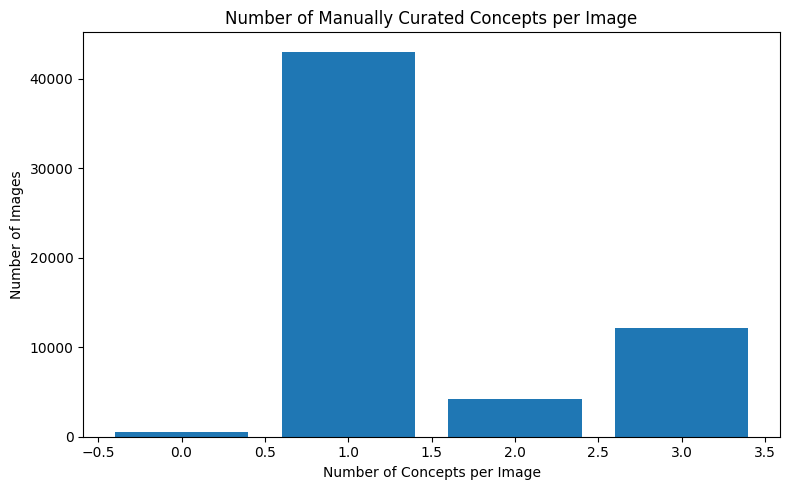

In [ ]:
# Multi-label plot
plt.figure(figsize=(8, 5))

plt.bar(
    label_distribution.index,
    label_distribution.values
)

plt.title(
    "Number of Manually Curated Concepts per Image"
)

plt.xlabel(
    "Number of Concepts per Image"
)

plt.ylabel(
    "Number of Images"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        EDA_DIR,
        "concepts_per_image.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Automatic vs manual concept vocabulary
# Load original automatic concepts

train_auto = pd.read_csv(
    f"{BASE_DIR}/Train/Concepts/train_concepts.csv"
)

auto_counter = Counter()

for value in train_auto["CUIs"].fillna(""):

    for cui in str(value).split(";"):

        cui = cui.strip()

        if cui:
            auto_counter[cui] += 1


comparison = pd.DataFrame({
    "Annotation Type": [
        "Automatic",
        "Manual"
    ],

    "Unique CUIs": [
        len(auto_counter),
        len(train_manual_counts)
    ],

    "Average Concepts/Image": [
        train_auto["CUIs"]
        .fillna("")
        .apply(
            lambda x: len(
                [
                    c for c in str(x).split(";")
                    if c.strip()
                ]
            )
        )
        .mean(),

        train_num_concepts.mean()
    ]
})

display(comparison)

,Annotation Type,Unique CUIs,Average Concepts/Image
0,Automatic,1947,3.347910
1,Manual,18,1.469195


In [ ]:
# Image existence verification
zip_files = {

    "Train":
        f"{BASE_DIR}/Train/Images/train_images.zip",

    "Validation":
        f"{BASE_DIR}/Validation/Images/valid_images.zip",

    "Test":
        f"{BASE_DIR}/Test/Images/test_images.zip"
}

zip_summary = []

for split, zip_path in zip_files.items():

    with zipfile.ZipFile(zip_path, "r") as z:

        files = [
            f for f in z.namelist()
            if not f.endswith("/")
        ]

    zip_summary.append({

        "Split": split,

        "ZIP Images": len(files),

        "Metadata Images": {
            "Train": len(train_df),
            "Validation": len(valid_df),
            "Test": len(test_df)
        }[split],

        "Difference":
            len(files) -
            {
                "Train": len(train_df),
                "Validation": len(valid_df),
                "Test": len(test_df)
            }[split]
    })


zip_summary = pd.DataFrame(zip_summary)

display(zip_summary)

,Split,ZIP Images,Metadata Images,Difference
0,Train,59958,59958,0
1,Validation,9904,9904,0
2,Test,9927,9927,0


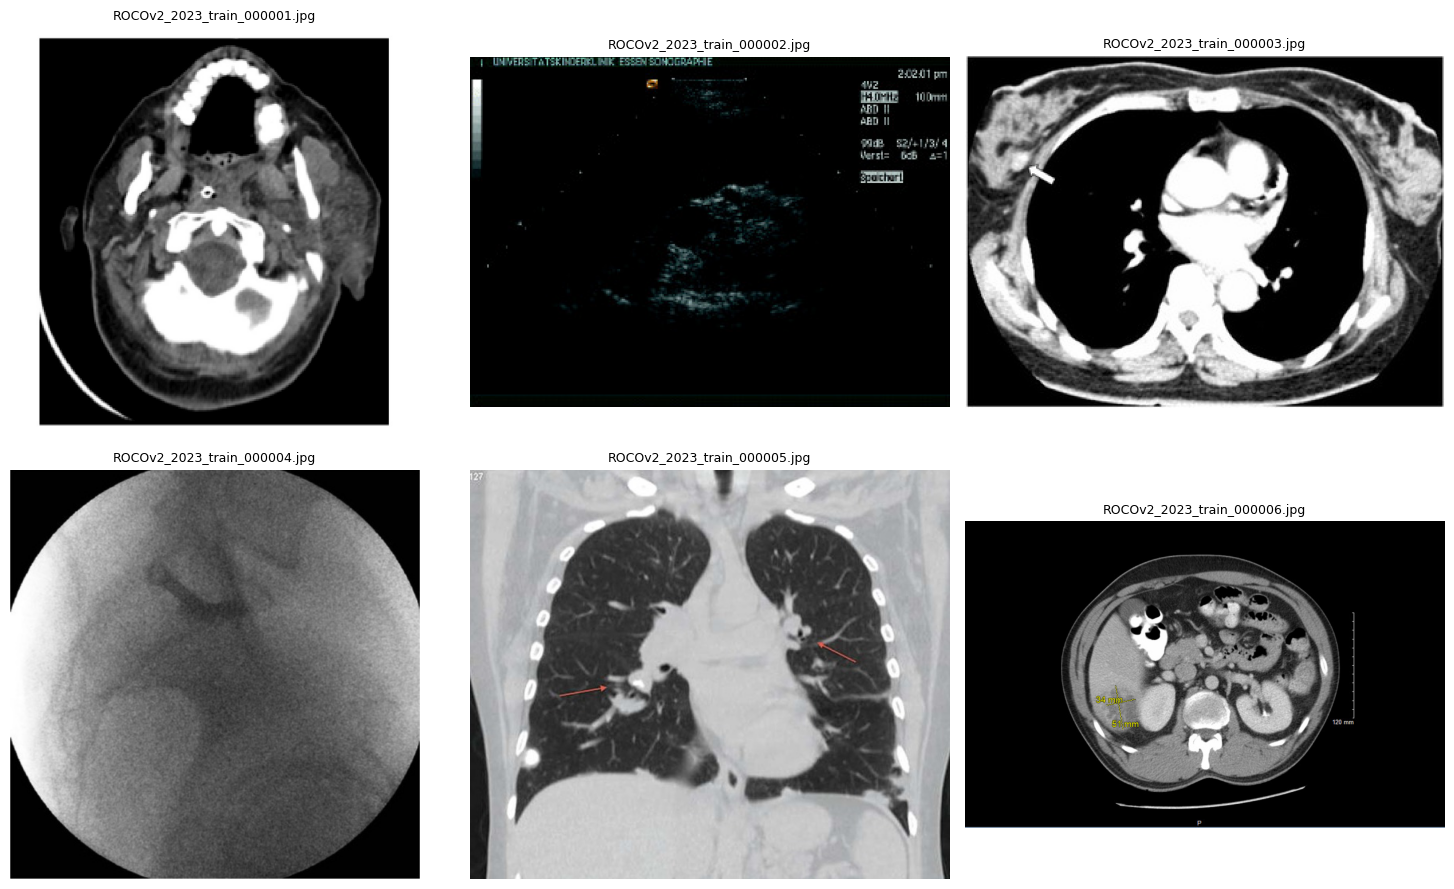

In [ ]:
# Image samples directly from ZIP
from PIL import Image
from io import BytesIO

train_zip_path = (
    f"{BASE_DIR}/Train/Images/train_images.zip"
)

with zipfile.ZipFile(
    train_zip_path,
    "r"
) as z:

    sample_names = [
        f
        for f in z.namelist()
        if f.endswith(".jpg")
    ][:6]

    images = []

    for name in sample_names:

        image_bytes = z.read(name)

        image = Image.open(
            BytesIO(image_bytes)
        ).convert("RGB")

        images.append(
            (name, image)
        )


fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 9)
)

for ax, (name, image) in zip(
    axes.ravel(),
    images
):

    ax.imshow(image)

    ax.set_title(
        os.path.basename(name),
        fontsize=9
    )

    ax.axis("off")

plt.tight_layout()

plt.savefig(
    os.path.join(
        EDA_DIR,
        "sample_images.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Match sample images with captions
sample_ids = [
    os.path.splitext(
        os.path.basename(name)
    )[0]
    for name, _ in images
]

sample_df = train_df[
    train_df["ID"].isin(sample_ids)
].copy()

display(
    sample_df[
        [
            "ID",
            "Caption",
            "Manual_Concepts",
            "Modality_Labels",
            "Anatomy_Labels",
            "Direction_Labels"
        ]
    ]
)

,ID,Caption,Manual_Concepts,Modality_Labels,Anatomy_Labels,Direction_Labels
0,ROCOv2_2023_train_000001,Head CT demonstrating left parotiditis.,CT,CT,NaN,NaN
1,ROCOv2_2023_train_000002,Acquired renal cysts in end-stage renal failur...,Ultrasound,Ultrasound,NaN,NaN
2,ROCOv2_2023_train_000003,Computed tomography of the chest showing the r...,CT,CT,NaN,NaN
3,ROCOv2_2023_train_000004,Lateral view of the sacrum showing the low con...,Angiogram,Angiogram,NaN,NaN
4,ROCOv2_2023_train_000005,Thoracic CT scan showing perihilar pulmonary l...,CT,CT,NaN,NaN
5,ROCOv2_2023_train_000006,5.1 cm x 3.4 cm x 4 cm multiloculated hepatic ...,CT,CT,NaN,NaN


In [ ]:
# Rare-class analysis
rare_threshold = 100

rare_labels = manual_concept_table[
    manual_concept_table["Train"] < rare_threshold
]

print(
    f"Labels with fewer than "
    f"{rare_threshold} training samples:"
)

display(rare_labels)

Labels with fewer than 100 training samples:


,CUI,Concept,Train,Validation,Test
16,C0006141,Breast,56,23,23
17,C0205106,Transverse - anatomical location,29,13,9


In [ ]:
# Dataset quality summary
quality_summary = {

    "Train samples": len(train_df),

    "Validation samples": len(valid_df),

    "Test samples": len(test_df),

    "Total samples":
        len(train_df) +
        len(valid_df) +
        len(test_df),

    "Manual concepts":
        len(train_manual_counts),

    "Automatic concepts":
        len(auto_counter),

    "Missing train captions":
        train_df["Caption"].isna().sum(),

    "Duplicate train IDs":
        train_df["ID"].duplicated().sum(),

    "Duplicate validation IDs":
        valid_df["ID"].duplicated().sum(),

    "Duplicate test IDs":
        test_df["ID"].duplicated().sum(),

    "Average manual concepts/image":
        train_num_concepts.mean(),

    "Minimum manual concepts/image":
        train_num_concepts.min(),

    "Maximum manual concepts/image":
        train_num_concepts.max()
}

quality_df = pd.DataFrame(
    quality_summary.items(),
    columns=[
        "Metric",
        "Value"
    ]
)

display(quality_df)

,Metric,Value
0,Train samples,59958.000000
1,Validation samples,9904.000000
2,Test samples,9927.000000
3,Total samples,79789.000000
4,Manual concepts,18.000000
5,Automatic concepts,1947.000000
6,Missing train captions,0.000000
7,Duplicate train IDs,0.000000
8,Duplicate validation IDs,0.000000
9,Duplicate test IDs,0.000000


In [ ]:
# Save EDA tables
# Save tables for later thesis/paper analysis

dataset_summary.to_csv(
    os.path.join(
        EDA_DIR,
        "dataset_split_summary.csv"
    ),
    index=False
)

manual_concept_table.to_csv(
    os.path.join(
        EDA_DIR,
        "manual_concept_distribution.csv"
    ),
    index=False
)

modality_table.to_csv(
    os.path.join(
        EDA_DIR,
        "modality_distribution.csv"
    ),
    index=False
)

anatomy_table.to_csv(
    os.path.join(
        EDA_DIR,
        "anatomy_distribution.csv"
    ),
    index=False
)

direction_table.to_csv(
    os.path.join(
        EDA_DIR,
        "directionality_distribution.csv"
    ),
    index=False
)

quality_df.to_csv(
    os.path.join(
        EDA_DIR,
        "dataset_quality_summary.csv"
    ),
    index=False
)

print("EDA tables saved to:")
print(EDA_DIR)

EDA tables saved to:
/content/drive/MyDrive/ROCOv2/EDA_Results


In [ ]:
# Final EDA report
print("=" * 90)
print("ROCOv2 — EDA FINAL SUMMARY")
print("=" * 90)

print(f"""
Dataset:
    ROCOv2

Total images:
    {len(train_df) + len(valid_df) + len(test_df):,}

Train:
    {len(train_df):,}

Validation:
    {len(valid_df):,}

Test:
    {len(test_df):,}

Manual concept vocabulary:
    {len(train_manual_counts)}

Automatic concept vocabulary:
    {len(auto_counter)}

Average manual concepts/image:
    {train_num_concepts.mean():.2f}

Maximum manual concepts/image:
    {train_num_concepts.max()}

Rare labels (<100 training images):
    {len(rare_labels)}

Dataset organization:
    Image + Caption + Manual Concepts

Proposed learning formulation:
    Multimodal Multi-Task Multi-Label Prediction
""")

ROCOv2 — EDA FINAL SUMMARY

Dataset:
    ROCOv2

Total images:
    79,789

Train:
    59,958

Validation:
    9,904

Test:
    9,927

Manual concept vocabulary:
    18

Automatic concept vocabulary:
    1947

Average manual concepts/image:
    1.47

Maximum manual concepts/image:
    3

Rare labels (<100 training images):
    2

Dataset organization:
    Image + Caption + Manual Concepts

Proposed learning formulation:
    Multimodal Multi-Task Multi-Label Prediction

